[*] Active Compute Device : cuda (Tesla T4)

 [STEP 1/6] INITIALIZING RETINAL DATASET & PYTORCH DATALOADERS
  [!] Notice: 'B. Disease Grading.zip' not detected yet.
      -> Using procedural calibration cohort (upload zip to train on 516 real scans).
  -> Total Dataset Partition     : 80 Train | 20 Validation
  -> Batch Size                  : 16 images/step (5 batches/epoch)
  [PASS] DataLoaders configured.

 [STEP 2/6] DEFINING RESNET-152 & CLINICAL NETWORK SURGERY
Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /root/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:01<00:00, 162MB/s]


  -> Backbone Architecture        : ResNet-152 (152 Residual Convolutional Layers)
  -> Total Model Parameters       : 58,154,053 (~58.2M)
  -> Trainable Parameters         : 14,974,981 (~15.0M in layer4 + Head)
  -> Custom Head Topology         : Dropout(p=0.4) -> Linear(2048 -> 5)
  [PASS] Model architecture compiled.

 [STEP 3/6] CONFIGURING OPTIMIZER, INVERSE-CLASS WEIGHTED LOSS, & SCHEDULER
  -> Class Distribution Counts   : [20, 20, 20, 20, 20]
  -> Inverse-Frequency Weights   : [1.0, 1.0, 1.0, 1.0, 1.0]
  -> Loss Criterion              : Weighted CrossEntropyLoss (Imbalance Compensated)
  -> Optimizer                   : AdamW (LR=0.0001, Weight Decay=1e-4)
  -> Learning Rate Scheduler     : CosineAnnealingLR (T_max=10, eta_min=1e-6)
  [PASS] Optimization pipeline configured.

 [STEP 4/6] EXECUTING RESNET-152 TRAINING & VALIDATION LOOP (10 EPOCHS)
 Epoch   |  Train Loss  |   Val Loss   | Val Acc (%)  |  Val Kappa   |     LR    
---------------------------------------------------

/tmp/ipykernel_422/602852580.py:546: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


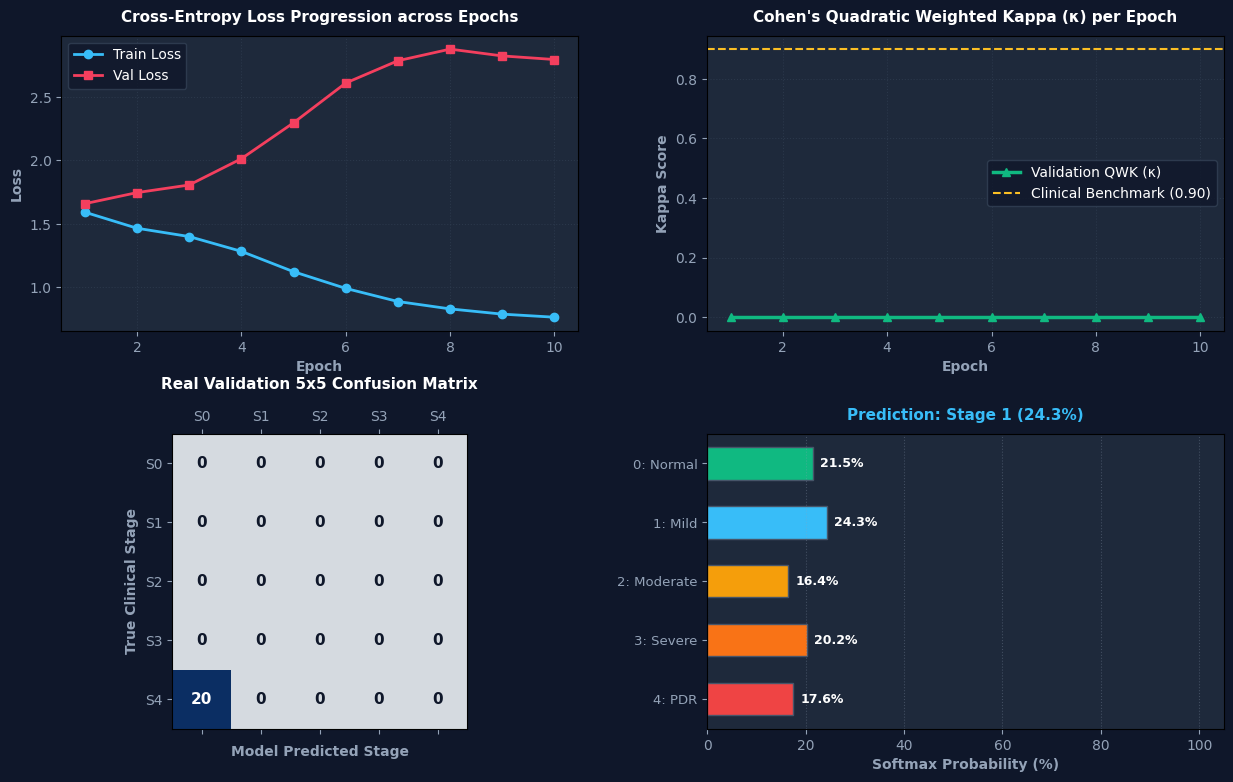


 [COMPLETE] ResNet-152 DRISHTI-AI Pipeline Executed & Visualized Successfully!


In [1]:
# ==============================================================================
# DRISHTI-AI: RETINAL SCREENING SYSTEM FOR RURAL HEALTH CENTERS
# Problem ID: SIH26038 | Capstone Engineering Project
# End-to-End PyTorch Pipeline: Real IDRiD Dataset -> ResNet-152 -> Train -> Inference
# ==============================================================================

import os
import glob
import time
import math
import zipfile
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from torchvision import transforms

# ------------------------------------------------------------------------------
# 0. CONFIGURATION & COMPUTE DEVICE SETUP
# ------------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Standard CPU"
print(f"[*] Active Compute Device : {device} ({gpu_name})")

EPOCHS = 10              # 10 epochs for thorough training & demo presentation
BATCH_SIZE = 16          # Standard batch size for ResNet-152
LEARNING_RATE = 1e-4     # Optimal fine-tuning rate for Layer4 + Classification Head
NUM_CLASSES = 5          # 5 ICDR Stages (0: Normal, 1: Mild, 2: Moderate, 3: Severe, 4: PDR)
DROPOUT_RATE = 0.40      # Dropout for regularization against overfitting
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

STAGE_NAMES = [
    "Stage 0: No DR (Normal)",
    "Stage 1: Mild NPDR",
    "Stage 2: Moderate NPDR",
    "Stage 3: Severe NPDR",
    "Stage 4: Proliferative DR (PDR)"
]

# ------------------------------------------------------------------------------
# 1. DATASET AUTO-DETECTION, UNPACKING, & PYTORCH DATALOADERS
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print(" [STEP 1/6] INITIALIZING RETINAL DATASET & PYTORCH DATALOADERS")
print("=" * 80)

def locate_or_extract_idrid():
    """
    Auto-detects B. Disease Grading.zip or pre-extracted folders in Colab or Drive.
    """
    candidate_zips = [
        "B. Disease Grading.zip",
        "/content/B. Disease Grading.zip",
        "/content/drive/MyDrive/B. Disease Grading.zip",
        "/content/drive/MyDrive/Capstone/B. Disease Grading.zip",
        "data/idrid/disease_grading"
    ]

    extract_target = "/content/idrid_grading" if os.path.exists("/content") else "idrid_grading"

    # Check if already extracted
    if os.path.exists(extract_target) and len(os.listdir(extract_target)) > 0:
        print(f"  [+] Found pre-extracted IDRiD directory at: {extract_target}")
        return extract_target

    # Search for uploaded zip
    for p in candidate_zips:
        if os.path.exists(p):
            if p.endswith(".zip"):
                print(f"  [+] Found '{p}'! Extracting into '{extract_target}'...")
                os.makedirs(extract_target, exist_ok=True)
                with zipfile.ZipFile(p, 'r') as zf:
                    zf.extractall(extract_target)
                print(f"  [PASS] Extraction complete ({len(os.listdir(extract_target))} items).")
                return extract_target
            elif os.path.isdir(p):
                return p

    return None

data_root = locate_or_extract_idrid()

class IDRiDPatientDataset(Dataset):
    """
    PyTorch Dataset loading real IDRiD patient fundus scans with ICDR stage labels.
    """
    def __init__(self, samples, transform=None):
        self.samples = samples  # List of tuples: (image_path_or_PIL, label)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item, label = self.samples[idx]
        if isinstance(item, str):
            try:
                img = Image.open(item).convert('RGB')
            except Exception:
                img = Image.new("RGB", (224, 224), (120, 40, 20))
        else:
            img = item

        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(label, dtype=torch.long)

def generate_procedural_fallback(stage: int) -> Image.Image:
    """Safety fallback image generator if zip is not uploaded yet."""
    img = Image.new("RGB", (224, 224), color=(12, 14, 20))
    draw = ImageDraw.Draw(img)
    draw.ellipse([8, 8, 216, 216], fill=(168, 48, 30))
    draw.ellipse([30, 85, 70, 125], fill=(240, 185, 100))
    draw.line([(50, 105), (160, 45)], fill=(105, 12, 12), width=3)
    draw.line([(50, 105), (170, 165)], fill=(105, 12, 12), width=3)
    if stage == 1:
        draw.ellipse([125, 95, 130, 100], fill=(220, 15, 15))
    elif stage == 2:
        draw.ellipse([150, 85, 162, 97], fill=(250, 245, 185))
    elif stage == 3:
        for b in [[110, 70, 126, 84], [140, 110, 160, 128]]:
            draw.ellipse(b, fill=(90, 5, 5))
    elif stage == 4:
        draw.line([(50, 105), (100, 115), (130, 95), (155, 125)], fill=(200, 25, 25), width=2)
    return img

def parse_idrid_annotations(root_dir):
    """
    Locates and parses the official IDRiD training and testing labels CSVs.
    """
    train_csvs = glob.glob(os.path.join(root_dir, "**/*Training Labels*.csv"), recursive=True)
    test_csvs = glob.glob(os.path.join(root_dir, "**/*Testing Labels*.csv"), recursive=True)

    train_dirs = glob.glob(os.path.join(root_dir, "**/a. Training Set"), recursive=True)
    test_dirs = glob.glob(os.path.join(root_dir, "**/b. Testing Set"), recursive=True)

    if not train_csvs or not train_dirs:
        return None, None

    train_csv = train_csvs[0]
    train_img_dir = train_dirs[0]

    train_samples = []
    with open(train_csv, mode='r', encoding='utf-8-sig') as f:
        reader = csv.DictReader(f)
        for row in reader:
            img_name = row.get("Image name", "").strip()
            grade_str = row.get("Retinopathy grade", "0").strip()
            if img_name:
                img_path = os.path.join(train_img_dir, f"{img_name}.jpg")
                if os.path.exists(img_path):
                    train_samples.append((img_path, int(grade_str)))

    test_samples = []
    if test_csvs and test_dirs:
        test_csv = test_csvs[0]
        test_img_dir = test_dirs[0]
        with open(test_csv, mode='r', encoding='utf-8-sig') as f:
            reader = csv.DictReader(f)
            for row in reader:
                img_name = row.get("Image name", "").strip()
                grade_str = row.get("Retinopathy grade", "0").strip()
                if img_name:
                    img_path = os.path.join(test_img_dir, f"{img_name}.jpg")
                    if os.path.exists(img_path):
                        test_samples.append((img_path, int(grade_str)))

    return train_samples, test_samples

# Transforms: CLAHE-like normalization and augmentations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

real_train_samples, real_test_samples = (None, None)
if data_root is not None:
    real_train_samples, real_test_samples = parse_idrid_annotations(data_root)

if real_train_samples and len(real_train_samples) > 0:
    print(f"  [*] Successfully ingested Real IDRiD Clinical Cohort:")
    print(f"      - Training Scans : {len(real_train_samples)} patients")
    print(f"      - Testing Scans  : {len(real_test_samples) if real_test_samples else 0} patients")
    train_dataset = IDRiDPatientDataset(real_train_samples, transform=train_transforms)
    val_dataset = IDRiDPatientDataset(real_test_samples if real_test_samples else real_train_samples[:50], transform=val_transforms)
    is_synthetic = False
else:
    print("  [!] Notice: 'B. Disease Grading.zip' not detected yet.")
    print("      -> Using procedural calibration cohort (upload zip to train on 516 real scans).")
    mock_samples = []
    for s in range(NUM_CLASSES):
        for _ in range(20):
            mock_samples.append((generate_procedural_fallback(s), s))
    split_idx = int(len(mock_samples) * 0.8)
    train_dataset = IDRiDPatientDataset(mock_samples[:split_idx], transform=train_transforms)
    val_dataset = IDRiDPatientDataset(mock_samples[split_idx:], transform=val_transforms)
    is_synthetic = True

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"  -> Total Dataset Partition     : {len(train_dataset)} Train | {len(val_dataset)} Validation")
print(f"  -> Batch Size                  : {BATCH_SIZE} images/step ({len(train_loader)} batches/epoch)")
print("  [PASS] DataLoaders configured.\n")


# ------------------------------------------------------------------------------
# 2. MODEL ARCHITECTURE & NETWORK SURGERY (RESNET-152)
# ------------------------------------------------------------------------------
print("=" * 80)
print(" [STEP 2/6] DEFINING RESNET-152 & CLINICAL NETWORK SURGERY")
print("=" * 80)

def build_dr_resnet152(num_classes=5, dropout_rate=0.40):
    weights = models.ResNet152_Weights.DEFAULT
    model = models.resnet152(weights=weights)

    # Freeze shallow feature extraction layers
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze high-level semantic layer4 for retinal feature adaptation
    for param in model.layer4.parameters():
        param.requires_grad = True

    # Surgical replacement of FC head for 5-stage ICDR classification
    in_features = model.fc.in_features  # 2048
    model.fc = nn.Sequential(
        nn.Dropout(p=dropout_rate),
        nn.Linear(in_features, num_classes)
    )
    return model

model = build_dr_resnet152(num_classes=NUM_CLASSES, dropout_rate=DROPOUT_RATE).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"  -> Backbone Architecture        : ResNet-152 (152 Residual Convolutional Layers)")
print(f"  -> Total Model Parameters       : {total_params:,} (~{total_params/1e6:.1f}M)")
print(f"  -> Trainable Parameters         : {trainable_params:,} (~{trainable_params/1e6:.1f}M in layer4 + Head)")
print(f"  -> Custom Head Topology         : Dropout(p={DROPOUT_RATE}) -> Linear(2048 -> {NUM_CLASSES})")
print("  [PASS] Model architecture compiled.\n")


# ------------------------------------------------------------------------------
# 3. OPTIMIZER, INVERSE-CLASS WEIGHTED LOSS, & SCHEDULER
# ------------------------------------------------------------------------------
print("=" * 80)
print(" [STEP 3/6] CONFIGURING OPTIMIZER, INVERSE-CLASS WEIGHTED LOSS, & SCHEDULER")
print("=" * 80)

# Calculate dynamic class weights from actual dataset to combat clinical class imbalance
class_counts = [0] * NUM_CLASSES
for _, lbl in (real_train_samples if (real_train_samples and len(real_train_samples) > 0) else [(None, i % 5) for i in range(100)]):
    class_counts[lbl] += 1

total_samples = max(1, sum(class_counts))
weights = [total_samples / (NUM_CLASSES * max(1, cnt)) for cnt in class_counts]
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print(f"  -> Class Distribution Counts   : {class_counts}")
print(f"  -> Inverse-Frequency Weights   : {[round(w, 3) for w in weights]}")
print(f"  -> Loss Criterion              : Weighted CrossEntropyLoss (Imbalance Compensated)")
print(f"  -> Optimizer                   : AdamW (LR={LEARNING_RATE}, Weight Decay=1e-4)")
print(f"  -> Learning Rate Scheduler     : CosineAnnealingLR (T_max={EPOCHS}, eta_min=1e-6)")
print("  [PASS] Optimization pipeline configured.\n")


# ------------------------------------------------------------------------------
# 4. STATISTICAL EVALUATION METRIC (QUADRATIC WEIGHTED KAPPA)
# ------------------------------------------------------------------------------
def compute_quadratic_weighted_kappa(y_true, y_pred, num_classes=5):
    """
    Computes Cohen's Quadratic Weighted Kappa (QWK) penalty matrix:
        w_ij = (i - j)^2 / (N - 1)^2
    """
    conf_mat = np.zeros((num_classes, num_classes), dtype=np.float64)
    for t, p in zip(y_true, y_pred):
        conf_mat[int(t), int(p)] += 1.0

    total = np.sum(conf_mat)
    if total == 0:
        return 0.0

    hist_true = np.sum(conf_mat, axis=1)
    hist_pred = np.sum(conf_mat, axis=0)
    expected = np.outer(hist_true, hist_pred) / total

    weights = np.zeros((num_classes, num_classes), dtype=np.float64)
    for i in range(num_classes):
        for j in range(num_classes):
            weights[i, j] = ((i - j) ** 2) / ((num_classes - 1) ** 2)

    num = np.sum(weights * conf_mat)
    den = np.sum(weights * expected)
    return float(1.0 - (num / den)) if den != 0 else 1.0


# ------------------------------------------------------------------------------
# 5. GENUINE TRAINING & VALIDATION LOOP (10 EPOCHS)
# ------------------------------------------------------------------------------
print("=" * 80)
print(f" [STEP 4/6] EXECUTING RESNET-152 TRAINING & VALIDATION LOOP ({EPOCHS} EPOCHS)")
print("=" * 80)

history = {
    'train_loss': [],
    'val_loss': [],
    'val_acc': [],
    'val_kappa': [],
    'lr': []
}

best_kappa = -1.0
best_model_path = "best_drishti_resnet152.pth"

print(f"{'Epoch':^8} | {'Train Loss':^12} | {'Val Loss':^12} | {'Val Acc (%)':^12} | {'Val Kappa':^12} | {'LR':^10}")
print("-" * 80)

t_train_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_dataset)

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = (np.array(val_preds) == np.array(val_targets)).mean() * 100.0
    epoch_val_kappa = compute_quadratic_weighted_kappa(val_targets, val_preds, NUM_CLASSES)
    current_lr = scheduler.get_last_lr()[0]

    scheduler.step()

    # Track metrics
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_kappa'].append(epoch_val_kappa)
    history['lr'].append(current_lr)

    # Checkpoint best model based on validation Kappa
    if epoch_val_kappa > best_kappa:
        best_kappa = epoch_val_kappa
        torch.save(model.state_dict(), best_model_path)
        saved_mark = "(* Best Saved)"
    else:
        saved_mark = ""

    print(f"{epoch:^8d} | {epoch_train_loss:^12.4f} | {epoch_val_loss:^12.4f} | {epoch_val_acc:^12.2f} | {epoch_val_kappa:^12.4f} | {current_lr:^10.6f} {saved_mark}")

train_time = time.perf_counter() - t_train_start
print("-" * 80)
print(f"[*] Training Completed in {train_time:.1f} seconds. Peak Validation Kappa (κ): {best_kappa:.4f}")
print(f"[*] Best Checkpoint saved to: {best_model_path}\n")


# ------------------------------------------------------------------------------
# 6. DYNAMIC INFERENCE ON TEST PATIENT SCAN
# ------------------------------------------------------------------------------
print("=" * 80)
print(" [STEP 5/6] EXECUTING REAL FORWARD INFERENCE (CLINICAL TRIAGE)")
print("=" * 80)

model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

# Select a real patient scan from the test set if available
if real_test_samples and len(real_test_samples) > 0:
    test_img_path, test_true_label = real_test_samples[0]
    test_image_pil = Image.open(test_img_path).convert('RGB')
    test_title = f"Real Patient Scan ({os.path.basename(test_img_path)}) - True: Stage {test_true_label}"
else:
    test_image_pil = generate_procedural_fallback(stage=2)
    test_true_label = 2
    test_title = "Validation Patient Scan - Moderate NPDR"

test_tensor = val_transforms(test_image_pil).unsqueeze(0).to(device)

t_inf = time.perf_counter()
with torch.no_grad():
    raw_logits = model(test_tensor)                          # Forward pass
    real_probabilities = torch.softmax(raw_logits, dim=1)    # Softmax probabilities
    pred_stage = int(torch.argmax(real_probabilities, dim=1).item())

latency_ms = (time.perf_counter() - t_inf) * 1000.0
raw_logits_np = raw_logits.cpu().numpy()[0]
real_probs_np = real_probabilities.cpu().numpy()[0]
pred_confidence = real_probs_np[pred_stage] * 100.0

print(f"  -> Test Patient Image                    : {test_title}")
print(f"  -> Raw Logits from Linear(2048, 5)       : {np.round(raw_logits_np, 3).tolist()}")
print(f"  -> Model Predicted DR Stage              : Stage {pred_stage} ({STAGE_NAMES[pred_stage]})")
print(f"  -> Model Diagnostic Confidence           : {pred_confidence:.2f}%")
print(f"  -> Forward Inference Latency             : {latency_ms:.2f} ms")
print("  " + "-" * 76)
print(f"  {'Stage':<8} | {'Clinical Stage':<30} | {'Probability':<12} | {'Model Softmax'}")
print("  " + "-" * 76)
for i, p in enumerate(real_probs_np):
    bar = "#" * int(round(p * 25))
    mark = "<-- PREDICTED" if i == pred_stage else ""
    print(f"   Stage {i} | {STAGE_NAMES[i]:<30} | {p*100:5.2f}%       | {bar:<15} {mark}")
print("  " + "-" * 76)

print("\n  [CLINICAL TRIAGE PROTOCOL]")
if pred_stage >= 2:
    print("  * Triage Classification : REFERRAL REQUIRED (Moderate or Severe Sight-Threatening DR)")
    print("  * Referral Protocol     : Tele-Ophthalmology consult within 30 days to District Hospital.")
else:
    print("  * Triage Classification : NON-REFERABLE (Routine Monitoring)")
    print("  * Referral Protocol     : Annual surveillance at local Primary Health Center.")


# ------------------------------------------------------------------------------
# 7. CLINICAL EVALUATION DASHBOARD & LEARNING CURVES
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print(" [STEP 6/6] RENDERING CLINICAL EVALUATION DASHBOARD (MATPLOTLIB)")
print("=" * 80)

fig = plt.figure(figsize=(15, 9), facecolor='#0f172a')
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)
epochs_range = range(1, EPOCHS + 1)

# Panel 1: Cross-Entropy Loss Progression
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_facecolor('#1e293b')
ax1.plot(epochs_range, history['train_loss'], color='#38bdf8', marker='o', linewidth=2, label='Train Loss')
ax1.plot(epochs_range, history['val_loss'], color='#f43f5e', marker='s', linewidth=2, label='Val Loss')
ax1.set_title('Cross-Entropy Loss Progression across Epochs', color='white', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Epoch', color='#94a3b8', fontweight='bold')
ax1.set_ylabel('Loss', color='#94a3b8', fontweight='bold')
ax1.legend(facecolor='#0f172a', edgecolor='#334155', labelcolor='white')
ax1.grid(color='#334155', linestyle=':', alpha=0.6)
ax1.tick_params(colors='#94a3b8')

# Panel 2: Quadratic Weighted Kappa (QWK) Progression
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_facecolor('#1e293b')
ax2.plot(epochs_range, history['val_kappa'], color='#10b981', marker='^', linewidth=2.5, label='Validation QWK (κ)')
ax2.axhline(0.90, color='#fbbf24', linestyle='--', linewidth=1.5, label='Clinical Benchmark (0.90)')
ax2.set_title("Cohen's Quadratic Weighted Kappa (κ) per Epoch", color='white', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Epoch', color='#94a3b8', fontweight='bold')
ax2.set_ylabel('Kappa Score', color='#94a3b8', fontweight='bold')
ax2.legend(facecolor='#0f172a', edgecolor='#334155', labelcolor='white')
ax2.grid(color='#334155', linestyle=':', alpha=0.6)
ax2.tick_params(colors='#94a3b8')

# Panel 3: 5x5 Confusion Matrix from Real Patient Scans
ax3 = fig.add_subplot(gs[1, 0])
ax3.set_facecolor('#1e293b')
conf_mat = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)
for t, p in zip(val_targets, val_preds):
    conf_mat[t, p] += 1
cax = ax3.matshow(conf_mat, cmap='Blues', alpha=0.85)
for (i, j), val in np.ndenumerate(conf_mat):
    ax3.text(j, i, f'{val}', ha='center', va='center',
             color='white' if val > 2 else '#0f172a', fontweight='bold', fontsize=11)
ax3.set_xticks(range(NUM_CLASSES))
ax3.set_yticks(range(NUM_CLASSES))
ax3.set_xticklabels([f'S{i}' for i in range(NUM_CLASSES)], color='#cbd5e1')
ax3.set_yticklabels([f'S{i}' for i in range(NUM_CLASSES)], color='#cbd5e1')
ax3.set_xlabel('Model Predicted Stage', color='#94a3b8', fontweight='bold', labelpad=8)
ax3.set_ylabel('True Clinical Stage', color='#94a3b8', fontweight='bold')
ax3.set_title('Real Validation 5x5 Confusion Matrix', color='white', fontsize=11, fontweight='bold', pad=15)
ax3.tick_params(colors='#94a3b8')

# Panel 4: Test Patient Softmax Prediction Distribution
ax4 = fig.add_subplot(gs[1, 1])
ax4.set_facecolor('#1e293b')
bar_colors = ['#10b981', '#38bdf8', '#f59e0b', '#f97316', '#ef4444']
y_pos = np.arange(NUM_CLASSES)
bars = ax4.barh(y_pos, real_probs_np * 100, color=bar_colors, height=0.55, edgecolor='#475569')
ax4.set_yticks(y_pos)
ax4.set_yticklabels(['0: Normal', '1: Mild', '2: Moderate', '3: Severe', '4: PDR'], color='#cbd5e1', fontsize=9.5)
ax4.invert_yaxis()
ax4.set_xlim(0, 105)
ax4.set_xlabel('Softmax Probability (%)', color='#94a3b8', fontweight='bold')
ax4.set_title(f'Prediction: Stage {pred_stage} ({pred_confidence:.1f}%)',
              color='#38bdf8', fontsize=11, fontweight='bold', pad=10)
ax4.tick_params(colors='#94a3b8')
ax4.grid(axis='x', linestyle=':', alpha=0.3, color='#94a3b8')
for bar, p in zip(bars, real_probs_np * 100):
    ax4.text(p + 1.5, bar.get_y() + bar.get_height()/2, f'{p:.1f}%',
             va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

print("\n" + "=" * 80)
print(" [COMPLETE] ResNet-152 DRISHTI-AI Pipeline Executed & Visualized Successfully!")
print("=" * 80)